# 01 · EDA

In [1]:
import sys; sys.path.insert(0, "../src")
import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import t3
from t3 import CFG, OUT, PRICE, SEED
from eval_utils import *

In [2]:
prices, articles, sent = t3.load_export()
print(prices.shape, articles.shape, sent.shape)
prices.groupby("split", sort=False).agg(n=("date", "size"), mulai=("date", "min"), akhir=("date", "max"))

(1194, 21) (4332, 12) (1202, 17)


,n,mulai,akhir
split,,,
train,836,2021-09-08,2025-02-18
val,178,2025-02-20,2025-11-20
test,180,2025-11-24,2026-08-31


## Harga
**Langkah pertama:** proporsi hari naik/turun per split, lalu bandingkan DirAcc Tugas 2 dengan baseline arah mayoritas.

In [3]:
sh = pd.DataFrame({s: {**up_share(g.target), **majority_baselines(g.target)} for s, g in prices.groupby("split", sort=False)}).T
display(sh.round(3))
maj = sh.loc["test", "Mayoritas"]
for k, v in {"Lasso/ElasticNet (collapse)": .591, "GradientBoosting + NLP": .597, "GradientBoosting baseline": .426}.items():
    print(f"{k:30s} DirAcc {v:.3f} | selisih thd mayoritas Test {v - maj:+.3f}")

,naik,turun,nol,Selalu naik,Selalu turun,Mayoritas
train,0.562,0.438,0.008,0.562,0.438,0.562
val,0.534,0.466,0.011,0.534,0.466,0.534
test,0.591,0.409,0.022,0.591,0.409,0.591


Lasso/ElasticNet (collapse)    DirAcc 0.591 | selisih thd mayoritas Test +0.000
GradientBoosting + NLP         DirAcc 0.597 | selisih thd mayoritas Test +0.006
GradientBoosting baseline      DirAcc 0.426 | selisih thd mayoritas Test -0.165


,std,skew,kurt
split,,,
train,0.003419,-0.408275,2.996644
val,0.003408,0.223496,3.349784
test,0.002895,-0.449594,1.851406


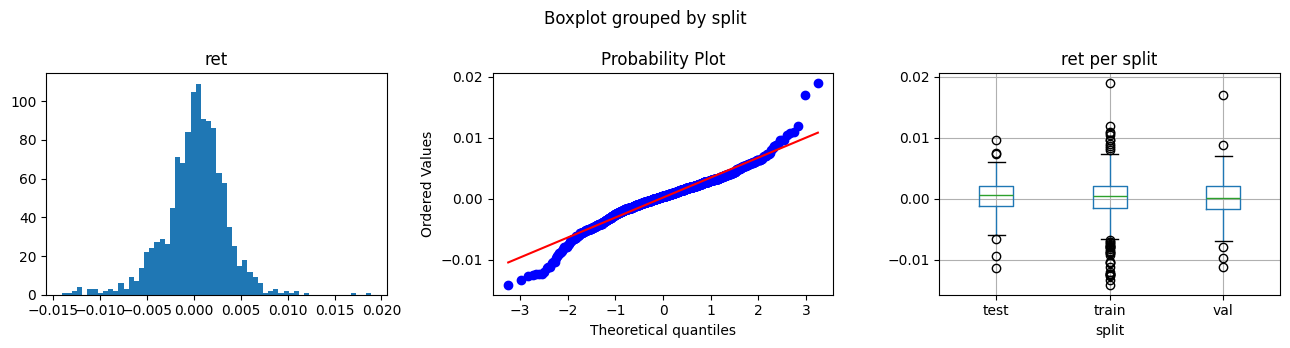

In [4]:
r = prices["ret"]
display(prices.groupby("split", sort=False)["ret"].agg(["std", "skew", lambda x: x.kurt()]).set_axis(["std", "skew", "kurt"], axis=1))
from scipy import stats
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(r, bins=60); ax[0].set_title("ret")
stats.probplot(r, plot=ax[1])
prices.boxplot("ret", by="split", ax=ax[2]); ax[2].set_title("ret per split")
t3.show("ret_dist")

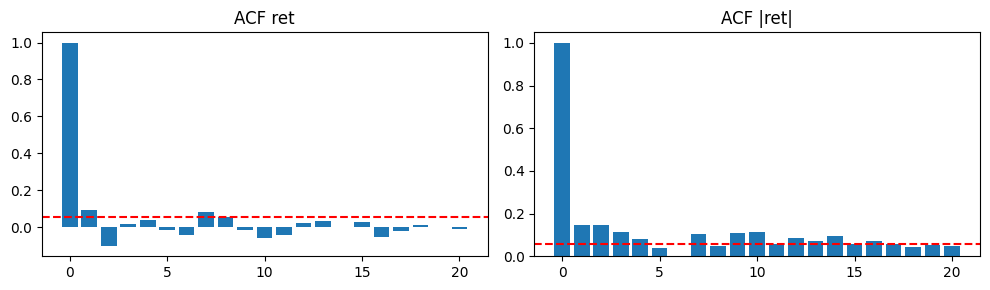

ADF p-value  kurs_mid: 0.858 | ret: 0.0000


In [7]:
from statsmodels.tsa.stattools import acf, adfuller
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, s, t in zip(ax, [r, r.abs()], ["ACF ret", "ACF |ret|"]):
    a.bar(range(21), acf(s, nlags=20)); a.axhline(2 / np.sqrt(len(s)), ls="--", c="r"); a.set_title(t)
t3.show("acf")
print(f"ADF p-value  kurs_mid: {adfuller(prices.kurs_mid)[1]:.3f} | ret: {adfuller(r)[1]:.4f}")

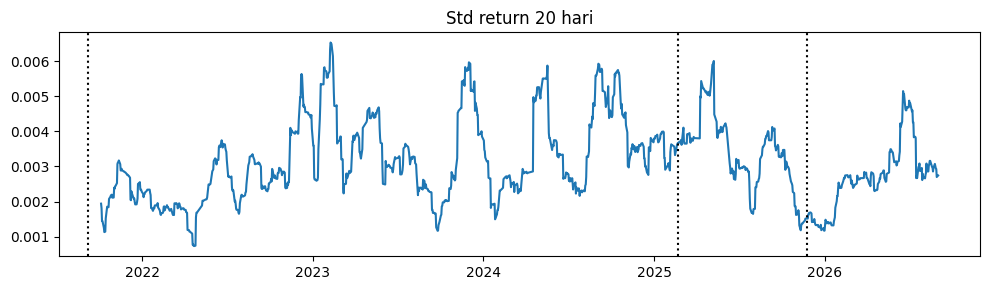

In [8]:
plt.figure(figsize=(10, 3)); plt.plot(prices.date, r.rolling(20).std())
for s, g in prices.groupby("split", sort=False): plt.axvline(g.date.min(), c="k", ls=":")
plt.title("Std return 20 hari"); t3.show("vol")

## Berita

Hari tanpa berita: 10.5% (126 dari 1202)


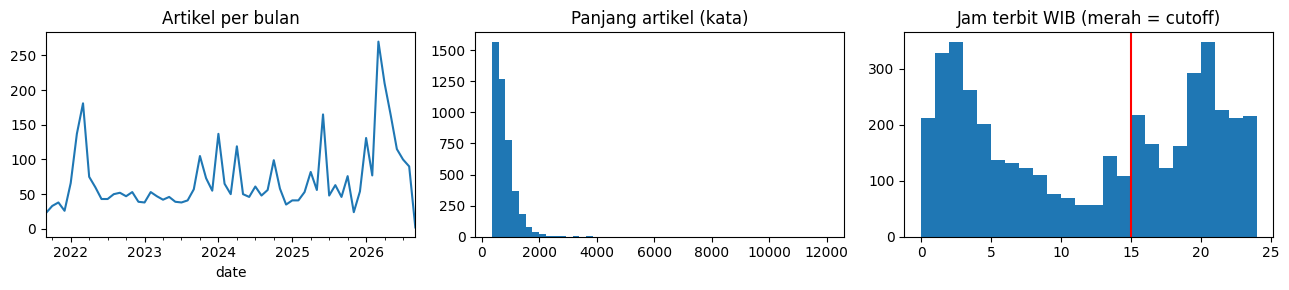

{'count': 4332.0, 'mean': 772.0, 'std': 412.0, 'min': 350.0, '25%': 511.0, '50%': 685.0, '75%': 913.0, 'max': 12028.0}


In [9]:
nd = sent["news_count"]
print(f"Hari tanpa berita: {(nd == 0).mean():.1%} ({(nd == 0).sum()} dari {len(nd)})")
words = articles.full_text.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
nd.resample("ME").sum().plot(ax=ax[0], title="Artikel per bulan")
ax[1].hist(words, bins=50); ax[1].set_title("Panjang artikel (kata)")
ax[2].hist(articles.jam.str[:2].astype(int), bins=range(25)); ax[2].axvline(15, c="r"); ax[2].set_title("Jam terbit WIB (merah = cutoff)")
t3.show("news")
print(words.describe().round(0).to_dict())

## Sentimen vs return

In [10]:
d = prices.merge(sent.reset_index(), on="date", how="left")
S = ["vader_title_mean", "lm_text_net", "lm_title_net"]
rows = {}
for c in S:
    for n, x in {"level": d[c], "lag1": d[c].shift(1), "roll5": d[c].rolling(5, min_periods=1).mean()}.items():
        rows[(c, n)] = {"corr ret_t+1": x.corr(d.target), "corr |ret_t+1|": x.corr(d.target.abs())}
display(pd.DataFrame(rows).T.round(3))
ll = pd.DataFrame({c: [d[c].shift(k).corr(d.target) for k in range(-3, 6)] for c in S}, index=pd.Index(range(-3, 6), name="k (k>0: sentimen k hari lalu)"))
display(ll.round(3))

corr ret_t+1  corr |ret_t+1|
vader_title_mean level         0.019          -0.008
                 lag1          0.001          -0.022
                 roll5        -0.007          -0.040
lm_text_net      level        -0.022          -0.036
                 lag1          0.019          -0.031
                 roll5         0.028          -0.050
lm_title_net     level         0.043           0.009
                 lag1          0.038          -0.034
                 roll5         0.064          -0.005

,vader_title_mean,lm_text_net,lm_title_net
k (k>0: sentimen k hari lalu),,,
-3,-0.017,-0.024,-0.031
-2,-0.002,0.000,0.008
-1,-0.000,-0.007,-0.026
0,0.019,-0.022,0.043
1,0.001,0.019,0.038
2,-0.019,0.034,-0.009
3,-0.012,0.028,0.046
4,-0.001,0.021,0.025
5,-0.014,0.004,-0.015


,vader_title_mean,lm_text_net,lm_title_net,fb_mean
vader_title_mean,1.00,0.32,0.41,0.31
lm_text_net,0.32,1.00,0.37,0.54
lm_title_net,0.41,0.37,1.00,0.27
fb_mean,0.31,0.54,0.27,1.00


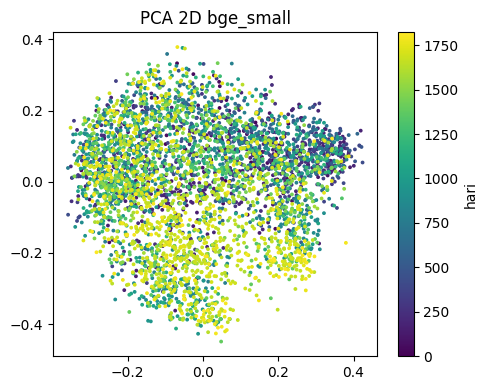

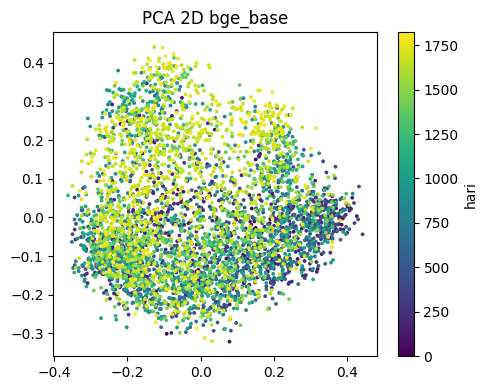

In [12]:
# FinBERT & embedding (jalan kalau cache sudah ada)
if (t3.EXPORT / "finbert_probs.npy").exists():
    fb = t3.daily_finbert(articles, t3.load_finbert(articles), sent.index)
    display(pd.concat([sent[S], fb["fb_mean"]], axis=1)[sent.news_count > 0].corr().round(2))
from sklearn.decomposition import PCA
for tag in CFG["emb_tags"]:
    if (t3.EXPORT / f"embeddings_{tag}.npy").exists():
        Z = PCA(2, random_state=SEED).fit_transform(t3.load_emb(tag, articles)[0])
        plt.figure(figsize=(5, 4)); plt.scatter(*Z.T, s=3, c=(articles.date - articles.date.min()).dt.days); plt.colorbar(label="hari")
        plt.title(f"PCA 2D {tag}"); t3.show(f"pca2d_{tag}")